In [1]:
import numpy as np
import pandas as pd
import os 

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Bidirectional
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

In [2]:
def transform_data(df):
    # 找欄位名稱
    data_index = df.columns[1:]
    # 壓縮成一維陣列
    flatten_data = df[data_index].values.reshape(-1)
    # 轉換成文字，並插入<SEP>作為分欄符號
    str_data = "<SEP>".join(flatten_data.astype('str'))
    # 將會計計數去除，並將無數值的轉成空白
    filter_data = str_data.replace(',',"").replace('X',"")
    # 透過"<SEP>"進行分割，並轉換成list
    x_data = filter_data.split("<SEP>")
    
    return x_data
    

In [3]:
x = []
for path in os.listdir('Stock'):
    file_path = f'Stock/{path}'
    df = pd.read_csv(file_path)
    data = transform_data(df)
    x.extend(data)

# 正規化
sc = MinMaxScaler()

# 串列轉換回陣列
x = np.array(x).astype('float')
# 根據資料欄更新
x = x.reshape(-1, len(df.columns[1:]))
x = sc.fit_transform(x)
# 取出收盤價當作標籤
y = x[:,5]

In [4]:
def split_data(datas,labels,split_num = 10):
    max_len = len(datas)
    x, y = [], []
    for i in range(max_len - split_num - 1):
        x.append(datas[i: i+split_num])
        y.append(labels[split_num+i+1])
    
    return np.array(x), np.array(y)

In [5]:
x_train,x_valid,y_train,y_valid = train_test_split(x,y,train_size=0.8,random_state=22,shuffle=False)

x_train,y_train = split_data(x_train, y_train)
x_valid,y_valid = split_data(x_valid, y_valid)

print(x_train)

[[[0.22257266 0.02551068 0.01179471 ... 0.01230425 0.492      0.02417809]
  [0.21602573 0.02444338 0.01179471 ... 0.01166507 0.48133333 0.02737848]
  [0.30007268 0.03500835 0.01099777 ... 0.01230425 0.492      0.03880555]
  ...
  [0.28291264 0.03203376 0.00860695 ... 0.00894855 0.476      0.03210831]
  [0.22106715 0.02450129 0.00956328 ... 0.00958773 0.492      0.0258625 ]
  [0.28411185 0.0323264  0.00844756 ... 0.01006711 0.49066667 0.03358723]]

 [[0.21602573 0.02444338 0.01179471 ... 0.01166507 0.48133333 0.02737848]
  [0.30007268 0.03500835 0.01099777 ... 0.01230425 0.492      0.03880555]
  [0.30335612 0.03553881 0.01163532 ... 0.01118568 0.47733333 0.03408245]
  ...
  [0.22106715 0.02450129 0.00956328 ... 0.00958773 0.492      0.0258625 ]
  [0.28411185 0.0323264  0.00844756 ... 0.01006711 0.49066667 0.03358723]
  [0.17026535 0.01829376 0.00828817 ... 0.00910834 0.47866667 0.02963559]]

 [[0.30007268 0.03500835 0.01099777 ... 0.01230425 0.492      0.03880555]
  [0.30335612 0.035538

In [8]:
model = Sequential()
model.add(
    Bidirectional(
        LSTM(
            128,
            input_shape=(x_train.shape[1],x_train.shape[-1]),
            return_sequences=True,
            activation='relu'
        )
    )
)
model.add(Bidirectional(LSTM(64,return_sequences=False,activation='relu')))
model.add(Dense(1))

model.compile(loss='mean_squared_error',optimizer='adam')
history = model.fit(x_train, y_train,
                    batch_size=64,
                    epochs=10,
                    verbose=1,
                    validation_data=(x_valid, y_valid)
                    )


20/20 [==============================] - 1s 6ms/step


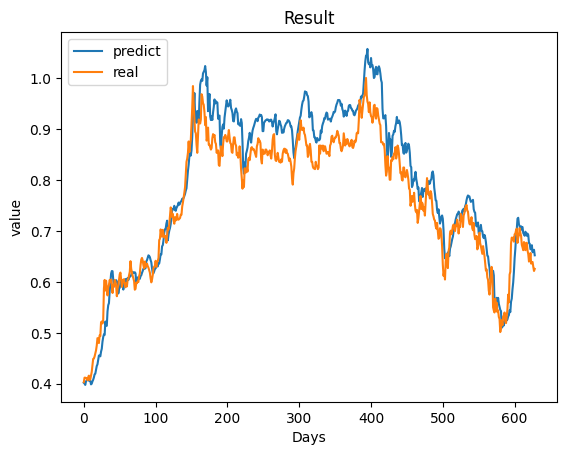

In [7]:
y_pred = model.predict(x_valid)

plt.plot(y_pred)
plt.plot(y_valid)

plt.title('Result')
plt.ylabel('value')
plt.xlabel('Days')

plt.legend(['predict', 'real'], loc='upper left')
plt.show()